# scimap spatial analysis

Interactive scimap on the cleaned cells (09's `filtered_data.csv`, exported by `scripts/15_scimap_anndata.py`).

- Kernel: **Python (scimap)** (see `envs/scimap.yml` / CLAUDE.md).
- Coordinates are in µm (`X_centroid`, `Y_centroid`), so every `radius` below is in µm.
- `imageid` = section (`code`), `phenotype` = `cell_type2`, so scimap's default argument names work.
- `X` = log1p(raw) intensities; `layers['log_dataset_z']` = the same z-scored per marker over all cells (capped at ±10). Only expression-based tools use them.

In [1]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import scimap as sm
import matplotlib.pyplot as plt
from scipy.stats import norm

PROJECT = os.environ.get("PCF_PROJECT", "/projects/b1169/boles/als_cns_pcf")
os.chdir(PROJECT)

REGION = "GM"        # "GM" or "WM"
RADIUS = 30          # um
N_PERM = 1000         # interactive; use 1000 for final numbers
OUT = f"results/15_scimap/{REGION}/"
os.makedirs(OUT, exist_ok=True)

adata = ad.read_h5ad("data/15_scimap_anndata/cells.h5ad")
adata = adata[adata.obs["region"] == REGION].copy()
adata

Running SCIMAP  2.4.1


/home/egn9175/.conda/envs/scimap/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AnnData object with n_obs × n_vars = 2164836 × 64
    obs: 'code', 'cell_id', 'cell_type', 'cell_type2', 'area_um2', 'region', 'has_dpr', 'has_ptdp', 'dist_dpr_um', 'dist_ptdp_um', 'dist_vessel_um', 'sample_id', 'tissue', 'sex', 'age', 'clinical_diagnosis', 'c9orf72_mutation', 'group', 'batch', 'x', 'y', 'X_centroid', 'Y_centroid', 'imageid', 'phenotype'
    var: 'log1p_mean', 'log1p_sd'
    uns: 'units'
    obsm: 'spatial'
    layers: 'log_dataset_z', None (.X)

## Composition per section

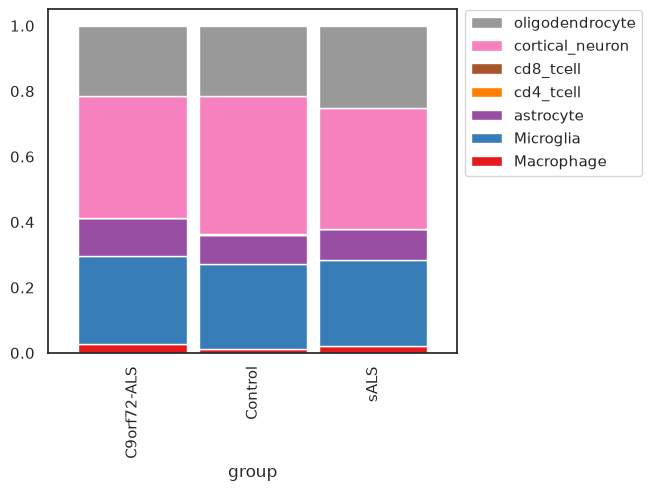

In [23]:
sm.pl.stacked_barplot(adata, x_axis="group", y_axis="phenotype", method="percent")

## A. Nearest distance between cell types

`spatial_distance` gives every cell its distance to the nearest cell of each type (a cell is excluded as its own neighbour for its own type). The section-level table below (median per section × from type × to type) is what group comparisons should use.

In [6]:
adata = sm.tl.spatial_distance (adata, 
                               x_coordinate='X_centroid', y_coordinate='Y_centroid', 
                               z_coordinate=None, 
                               phenotype='phenotype', 
                               subset=None, 
                               imageid='imageid', 
                               label='spatial_distance')

Processing Image: 160-1
Processing Image: 161-1
Processing Image: 161-3
Processing Image: 161-5
Processing Image: 161-7
Processing Image: 162-1
Processing Image: 162-3
Processing Image: 162-5
Processing Image: 162-7
Processing Image: 166-7
Processing Image: 168-1
Processing Image: 168-3
Processing Image: 168-5
Processing Image: 168-7
Processing Image: 169-1
Processing Image: 169-3
Processing Image: 169-5
Processing Image: 169-7
Processing Image: 169-9
Processing Image: 170-1
Processing Image: 170-3


In [8]:
adata.uns["spatial_distance"].head

<bound method NDFrame.head of                               astrocyte    cd4_tcell    cd8_tcell  \
160-1_astrocyte_1             38.925823  1970.538164  3667.113217   
160-1_astrocyte_3             38.925823  1966.824273  3662.983339   
160-1_astrocyte_4             64.982557  2043.751520  3735.847004   
160-1_astrocyte_5             34.382580  1927.102534  3623.281942   
160-1_astrocyte_6             42.979634  1955.433341  3650.645925   
...                                 ...          ...          ...   
170-3_oligodendrocyte_94817   56.120586   311.163016   674.762407   
170-3_oligodendrocyte_94818  126.285113   606.511857   165.640566   
170-3_oligodendrocyte_94819   15.271325   818.519737   466.765187   
170-3_oligodendrocyte_94820   43.631428   389.689997   310.746490   
170-3_oligodendrocyte_94821   26.447872   524.911996   176.988605   

                             cortical_neuron   Microglia  Macrophage  \
160-1_astrocyte_1                  40.128414   20.842733   86.257507 

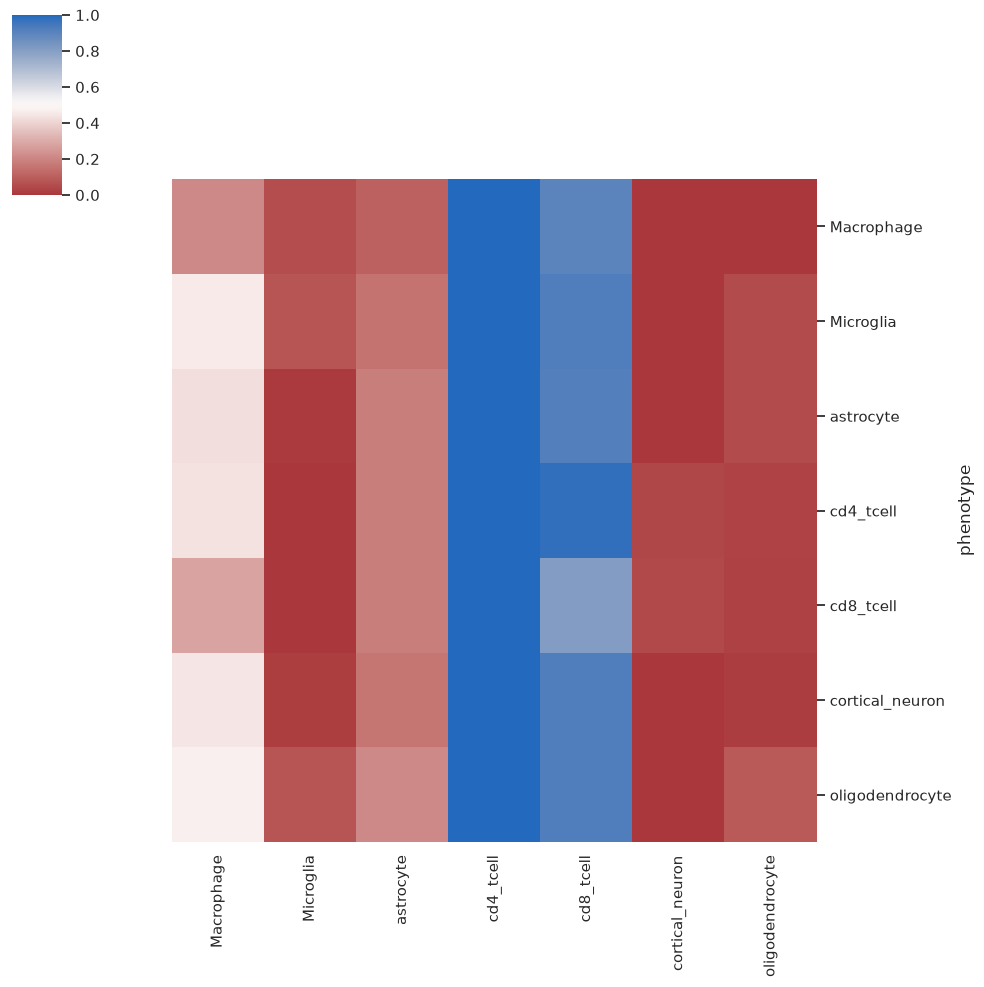

In [12]:
sm.pl.spatial_distance(adata, heatmap_summarize=True, log=True)

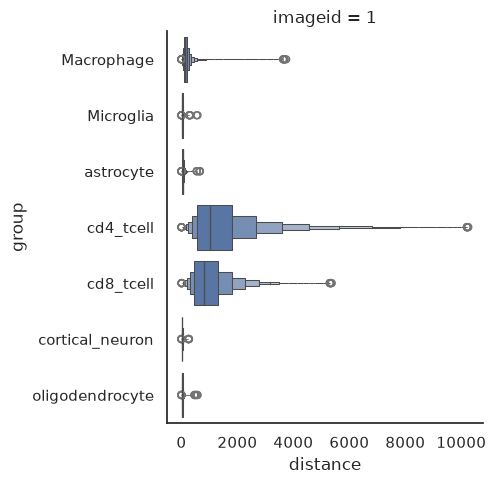

In [18]:
adata.obs["dummy"]=1
sm.pl.spatial_distance (adata, method='numeric',distance_from='cortical_neuron', imageid="dummy")

In [5]:
dist = adata.uns["spatial_distance"]
d = dist.join(adata.obs[["imageid", "phenotype", "group", "sample_id"]])
nearest = (d.melt(id_vars=["imageid", "phenotype", "group", "sample_id"], var_name="to_type", value_name="dist_um")
             .groupby(["imageid", "group", "sample_id", "phenotype", "to_type"], observed=True)["dist_um"]
             .median().rename("median_dist_um").reset_index()
             .rename(columns={"imageid": "code", "phenotype": "from_type"}))
nearest.to_csv(OUT + "nearest_distance_medians.csv", index=False)
nearest.head()

,code,group,sample_id,from_type,to_type,median_dist_um
0,160-1,C9orf72-ALS,GBB1607,Macrophage,Macrophage,56.633860
1,160-1,C9orf72-ALS,GBB1607,Macrophage,Microglia,31.367073
2,160-1,C9orf72-ALS,GBB1607,Macrophage,astrocyte,37.049284
3,160-1,C9orf72-ALS,GBB1607,Macrophage,cd4_tcell,1089.885098
4,160-1,C9orf72-ALS,GBB1607,Macrophage,cd8_tcell,709.093495


## B. Neighbour interactions within a radius

`spatial_interaction` counts neighbours within `RADIUS` and compares them with `N_PERM` shuffles of the neighbours' labels, per section. In its output, each section's value is the neighbour frequency scaled to the row's maximum, signed by whether it is above (+) or below (−) the shuffled mean, and `pvalue_<section>` is a z-test p-value. That scaled value is not an observed/expected ratio, so the signed z recovered below (from the sign and p-value) is the per-section effect to compare between groups.

Processing Image: ['160-1']
Categories (1, str): ['160-1']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 200 permutations
Consolidating the permutation results
Processing Image: ['161-1']
Categories (1, str): ['161-1']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 200 permutations
Consolidating the permutation results
Processing Image: ['161-3']
Categories (1, str): ['161-3']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 200 permutations
Consolidating the permutation results
Processing Image: ['161-5']
Categories (1, str): ['161-5']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 200 permutations
Consolidating the permutation results
Processing Image: ['161-7']
Categories (1, str): ['161-7']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 200 p

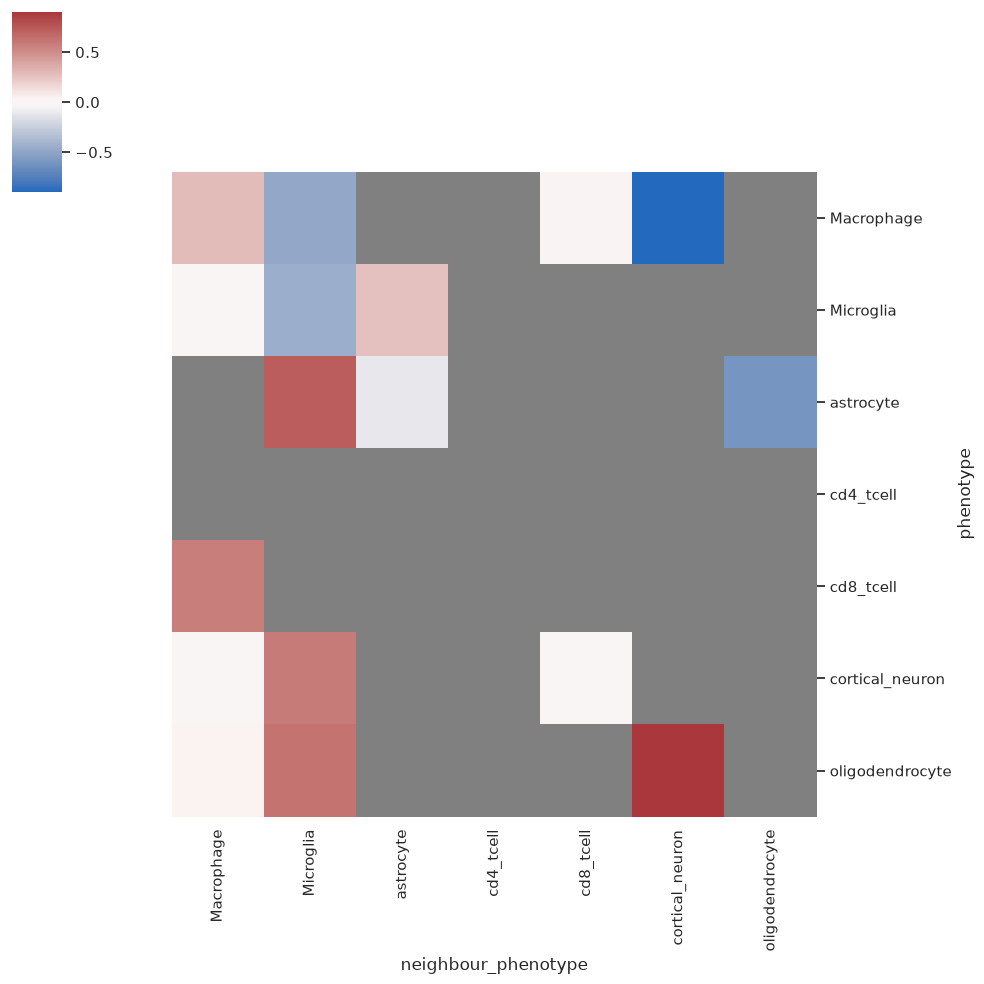

In [19]:
adata = sm.tl.spatial_interaction(adata, phenotype="phenotype", imageid="imageid",
                                  method="radius", radius=RADIUS, permutation=N_PERM,
                                  label="spatial_interaction")
sm.pl.spatial_interaction(adata, spatial_interaction="spatial_interaction", p_val=0.05)

In [20]:
si = adata.uns["spatial_interaction"]
codes = [c for c in si.columns if c not in ("phenotype", "neighbour_phenotype") and not c.startswith("pvalue_")]
rows = []
for c in codes:
    t = si[["phenotype", "neighbour_phenotype", c, "pvalue_" + c]].copy()
    t.columns = ["from_type", "to_type", "score", "p"]
    t["code"] = c
    rows.append(t)
inter = pd.concat(rows, ignore_index=True)
inter["z"] = np.sign(inter["score"]) * norm.isf(inter["p"].clip(lower=1e-300) / 2)
meta = adata.obs[["imageid", "group", "sample_id"]].drop_duplicates().rename(columns={"imageid": "code"})
inter = inter.merge(meta, on="code")
inter.to_csv(OUT + f"interaction_r{RADIUS}.csv", index=False)
inter.head()

,from_type,to_type,score,p,code,z,group,sample_id
0,Macrophage,Macrophage,0.229636,1.208513e-263,160-1,34.687677,C9orf72-ALS,GBB1607
1,Macrophage,Microglia,-0.557307,8.463455e-111,160-1,-22.365861,C9orf72-ALS,GBB1607
2,Macrophage,astrocyte,-0.380270,1.106488e-02,160-1,-2.540643,C9orf72-ALS,GBB1607
3,Macrophage,cd4_tcell,0.002047,2.375969e-06,160-1,4.718494,C9orf72-ALS,GBB1607
4,Macrophage,cd8_tcell,0.007777,3.775058e-19,160-1,8.943362,C9orf72-ALS,GBB1607


## Neighbourhoods (exploratory)

Cell-type composition within `RADIUS` of each cell, then k-means into `k` neighbourhoods (the Schürch 2020 / scimap approach).

Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours within 30 pixels of every cell
Identifying neighbours withi

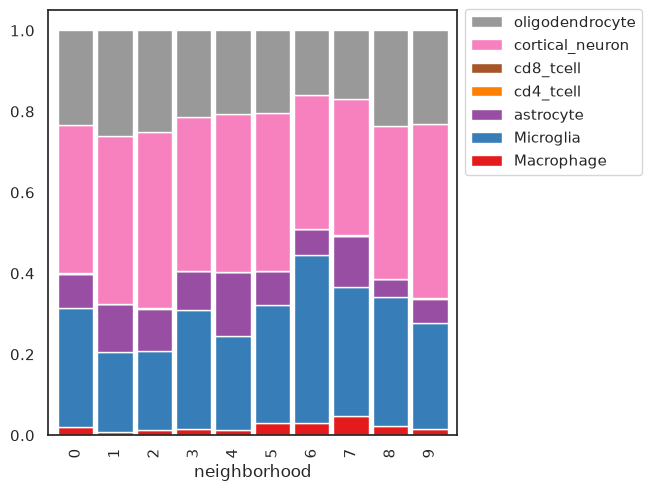

In [21]:
adata = sm.tl.spatial_count(adata, phenotype="phenotype", imageid="imageid", method="radius", radius=RADIUS,
                            label="spatial_count")
adata = sm.tl.spatial_cluster(adata, df_name="spatial_count", method="kmeans", k=10, label="neighborhood")
sm.pl.stacked_barplot(adata, x_axis="neighborhood", y_axis="phenotype", method="percent")

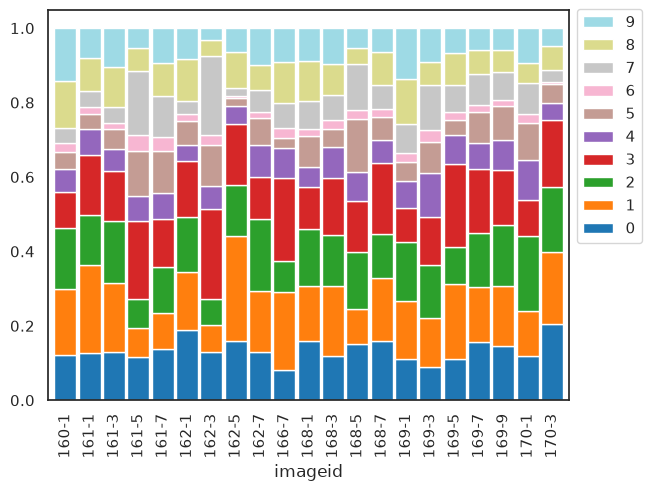

In [22]:
sm.pl.stacked_barplot(adata, x_axis="imageid", y_axis="neighborhood", method="percent")

In [ ]:
adata.write_h5ad(OUT + "cells_scimap.h5ad")